# 03 — Model Training & Evaluation

**Input:** `data/processed/movies_processed.parquet` (created by the PySpark notebook 01)
**Outputs:** `models/best_model.pkl`, `models/model_metadata.json`, `models/model_comparison.csv`,
`models/test_predictions.parquet`, `models/feature_importance.csv`, figures in `reports/figures/`

### Relationship between the Spark pipeline and the ML pipeline
All cleaning and feature creation (type casting, de-duplication, genre parsing, log-budget, flags…) was done
once, in Spark, in notebook 01. This notebook only applies **model-specific** transformations — scaling and
one-hot encoding — inside a scikit-learn `Pipeline`, so they are **fitted on the training set only** and the
very same fitted objects are reused at prediction time by the dashboard. scikit-learn is used for modelling
because the cleaned dataset fits easily in memory and its tooling (pipelines, CV search, permutation importance)
is simpler and more reliable for a dataset of this size than Spark MLlib.

### Prediction scenario
*"Given what is known about a movie **before release**, how popular will it be on TMDB?"*
- **Target:** `log_popularity = log(1 + popularity)`. Raw popularity is extremely right-skewed (a few
  blockbusters score > 100 while the median is ≈ 1–2); the log makes errors comparable across movies.
- **No leakage:** `revenue`, `vote_count`, `vote_average` and MovieLens ratings are post-release and are excluded.
- **Caveat:** TMDB popularity is a *snapshot* (collected ~2017) driven by recent page views, votes and
  watch-list activity — it is not a fixed pre-release outcome, so a large part of its variance is not
  explainable from metadata alone.

## 1. Load data and define features

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = PROJECT_ROOT / "data" / "processed"
MODELS = PROJECT_ROOT / "models"
FIG = PROJECT_ROOT / "reports" / "figures"
MODELS.mkdir(exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA / "movies_processed.parquet")
proc_meta = json.loads((DATA / "processing_metadata.json").read_text())
GENRE_COLS = proc_meta["genre_columns"]
print(df.shape)

(44861, 46)


In [2]:
NUMERIC_FEATURES = ["log_budget", "budget_known", "runtime", "release_year", "release_month",
                    "num_genres", "has_collection", "num_companies", "num_countries",
                    "is_us_production"] + GENRE_COLS
CATEGORICAL_FEATURES = ["original_language"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "log_popularity"
LEAKY = ["revenue", "vote_count", "vote_average", "popularity", "log_popularity"]
assert not set(FEATURES) & set(LEAKY), "leakage: post-release column in features"

X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"train: {len(X_train)}  test: {len(X_test)}  features: {len(FEATURES)}")
assert set(X_train.index).isdisjoint(X_test.index)

train: 35888  test: 8973  features: 31


## 2. Preprocessing pipeline
- **Numeric:** `StandardScaler` (needed by Linear Regression, harmless for trees).
- **Categorical (`original_language`):** `OneHotEncoder` — languages with < 100 training movies are grouped into an
  *infrequent* bucket; unseen languages at prediction time are mapped to that bucket instead of crashing.

In [3]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False),
         CATEGORICAL_FEATURES),
    ])

def make_pipeline(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

## 3. Train and tune models
Hyper-parameters are chosen with **3-fold cross-validation on the training set only** (scoring = RMSE).
The test set is used once, at the end, for the final comparison.

In [4]:
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
SCORING = "neg_root_mean_squared_error"

candidates = {
    "Baseline (mean)": (make_pipeline(DummyRegressor()), None),
    "Linear Regression": (make_pipeline(LinearRegression()), None),
    "Decision Tree": (make_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)),
                      {"model__max_depth": [6, 8, 10, 12], "model__min_samples_leaf": [10, 30, 60]}),
    "Random Forest": (make_pipeline(RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)),
                      {"model__max_depth": [12, 18, None], "model__min_samples_leaf": [2, 5, 10],
                       "model__max_features": [0.3, 0.5]}),
    "Gradient Boosting": (make_pipeline(HistGradientBoostingRegressor(max_iter=400, random_state=RANDOM_STATE)),
                          {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [15, 31, 63],
                           "model__min_samples_leaf": [20, 50]}),
}

fitted, cv_scores, best_params, train_time = {}, {}, {}, {}
for name, (pipe, grid) in candidates.items():
    t0 = time.time()
    if grid is None:
        from sklearn.model_selection import cross_val_score
        cv_scores[name] = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring=SCORING).mean()
        pipe.fit(X_train, y_train)
        fitted[name], best_params[name] = pipe, {}
    else:
        n_combos = np.prod([len(v) for v in grid.values()])
        search = (GridSearchCV(pipe, grid, cv=cv, scoring=SCORING, n_jobs=-1) if n_combos <= 12 else
                  RandomizedSearchCV(pipe, grid, n_iter=10, cv=cv, scoring=SCORING, n_jobs=-1,
                                     random_state=RANDOM_STATE))
        search.fit(X_train, y_train)
        fitted[name] = search.best_estimator_
        cv_scores[name] = -search.best_score_
        best_params[name] = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    train_time[name] = round(time.time() - t0, 1)
    print(f"{name:18s} CV RMSE (log) = {cv_scores[name]:.4f}   {train_time[name]:6.1f}s   {best_params[name]}")

Baseline (mean)    CV RMSE (log) = 0.8053      0.6s   {}
Linear Regression  CV RMSE (log) = 0.5711      0.7s   {}
Decision Tree      CV RMSE (log) = 0.5672     10.5s   {'max_depth': 12, 'min_samples_leaf': 60}
Random Forest      CV RMSE (log) = 0.5373     67.7s   {'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': None}
Gradient Boosting  CV RMSE (log) = 0.5329     29.8s   {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 50}


## 4. Evaluate on the held-out test set

| Metric | Plain-language meaning |
|--------|------------------------|
| **MAE** | Average size of the error. On the log scale, MAE = 0.5 means predictions are typically off by a factor of ≈ e^0.5 ≈ 1.65×. |
| **RMSE** | Like MAE but squares errors first, so big misses count more. |
| **R²** | Share of the variation in popularity the model explains: 0 = no better than predicting the average, 1 = perfect. |

We report the metrics on the **log scale** (what the model optimises) and on the **original popularity scale**.

In [5]:
def metrics(y_true_log, y_pred_log):
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {
        "MAE (log)": mean_absolute_error(y_true_log, y_pred_log),
        "RMSE (log)": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "R² (log)": r2_score(y_true_log, y_pred_log),
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": np.sqrt(mean_squared_error(yt, yp)),
        "R²": r2_score(yt, yp),
    }

rows, test_preds = [], {}
for name, model in fitted.items():
    test_preds[name] = model.predict(X_test)
    rows.append({"Model": name, "CV RMSE (log)": cv_scores[name], **metrics(y_test, test_preds[name]),
                 "Train time (s)": train_time[name]})
comparison = pd.DataFrame(rows).round(4)

# Best model = lowest cross-validated RMSE (selection does not peek at the test set)
best_name = comparison.loc[comparison["Model"] != "Baseline (mean)"].sort_values("CV RMSE (log)").iloc[0]["Model"]
comparison["Selected"] = np.where(comparison["Model"] == best_name, "✔ best", "")
comparison

,Model,CV RMSE (log),MAE (log),RMSE (log),R² (log),MAE,RMSE,R²,Train time (s),Selected
0,Baseline (mean),0.8053,0.6672,0.8008,-0.0001,2.5699,7.9181,-0.0260,0.6,
1,Linear Regression,0.5711,0.4440,0.5661,0.5001,1.8325,7.1619,0.1606,0.7,
2,Decision Tree,0.5672,0.4337,0.5609,0.5092,1.7833,7.0953,0.1761,10.5,
3,Random Forest,0.5373,0.4090,0.5294,0.5628,1.6859,7.0381,0.1894,67.7,
4,Gradient Boosting,0.5329,0.4034,0.5231,0.5733,1.6756,6.9921,0.1999,29.8,✔ best


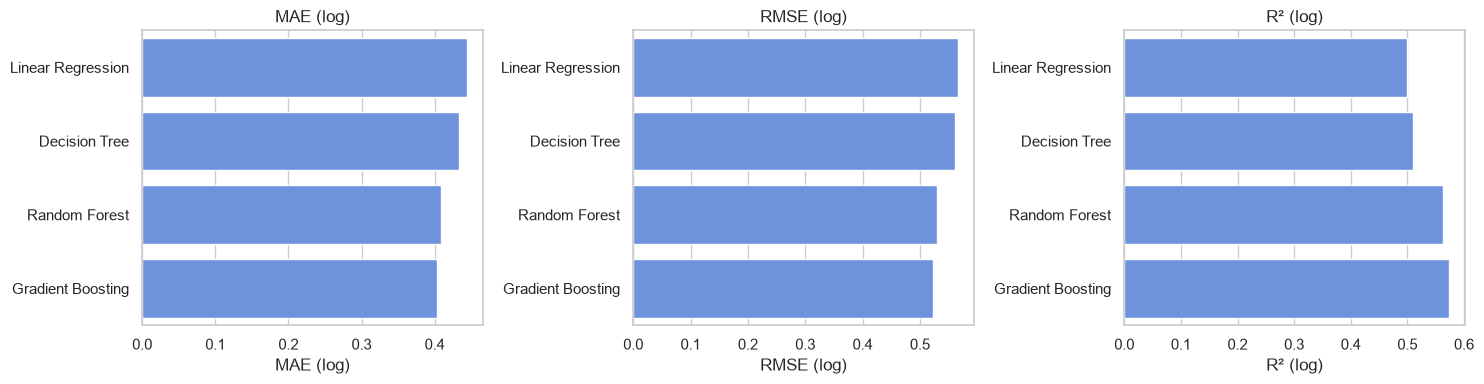

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_df = comparison[comparison["Model"] != "Baseline (mean)"]
for ax, m in zip(axes, ["MAE (log)", "RMSE (log)", "R² (log)"]):
    sns.barplot(data=plot_df, x=m, y="Model", ax=ax, color="#5b8def")
    ax.set_title(m); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "model_comparison.png", dpi=130); plt.show()

## 5. Best model — actual vs predicted and residuals

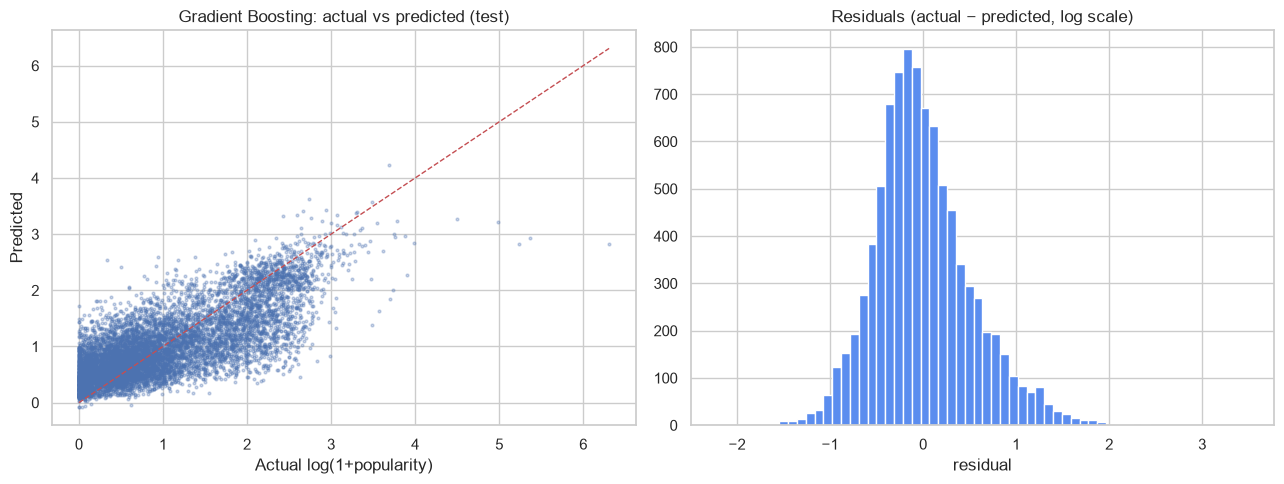

In [7]:
best_model = fitted[best_name]
y_pred = test_preds[best_name]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred, s=4, alpha=0.3)
lims = [0, max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, "r--", lw=1)
axes[0].set(xlabel="Actual log(1+popularity)", ylabel="Predicted", title=f"{best_name}: actual vs predicted (test)")
axes[1].hist(y_test - y_pred, bins=60, color="#5b8def")
axes[1].set(title="Residuals (actual − predicted, log scale)", xlabel="residual")
plt.tight_layout(); plt.savefig(FIG / "actual_vs_predicted.png", dpi=130); plt.show()

## 6. Feature importance
We use **permutation importance** on the test set: each original input column is shuffled and we measure how
much the RMSE gets worse. It works for every model type and is expressed in terms of the original features
(e.g. *original_language* as a whole rather than one column per language).

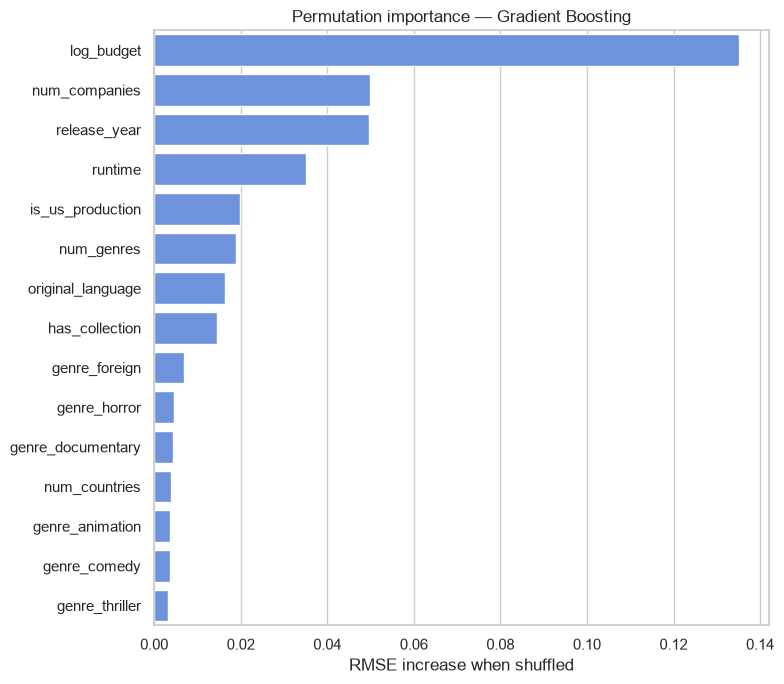

,feature,importance,std
0,log_budget,0.135190,0.003929
1,num_companies,0.049798,0.002409
2,release_year,0.049679,0.002662
3,runtime,0.034991,0.000916
4,is_us_production,0.019905,0.001138
5,num_genres,0.018925,0.000753
6,original_language,0.016395,0.002179
7,has_collection,0.014404,0.001477
8,genre_foreign,0.006781,0.000446
9,genre_horror,0.004531,0.000669


In [8]:
sample = X_test.sample(min(4000, len(X_test)), random_state=RANDOM_STATE)
perm = permutation_importance(best_model, sample, y_test.loc[sample.index], n_repeats=5,
                              random_state=RANDOM_STATE, scoring=SCORING)
importance = (pd.DataFrame({"feature": FEATURES, "importance": perm.importances_mean, "std": perm.importances_std})
              .sort_values("importance", ascending=False).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(data=importance.head(15), x="importance", y="feature", color="#5b8def", ax=ax)
ax.set(title=f"Permutation importance — {best_name}", xlabel="RMSE increase when shuffled", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "feature_importance.png", dpi=130); plt.show()
importance.head(15)

## 7. Save model and evaluation artefacts

In [9]:
joblib.dump(best_model, MODELS / "best_model.pkl", compress=3)
comparison.to_csv(MODELS / "model_comparison.csv", index=False)
importance.to_csv(MODELS / "feature_importance.csv", index=False)

pred_df = df.loc[X_test.index, ["id", "title", "release_year", "primary_genre", "popularity"]].copy()
pred_df["actual_log"] = y_test.values
for name, p in test_preds.items():
    pred_df[f"pred_log__{name}"] = p
pred_df.to_parquet(MODELS / "test_predictions.parquet", index=False)

best_row = comparison.set_index("Model").loc[best_name]
metadata = {
    "best_model": best_name,
    "best_params": {k: (v if not isinstance(v, (np.integer, np.floating)) else v.item()) for k, v in best_params[best_name].items()},
    "target": TARGET,
    "target_transform": "log1p(popularity); invert with expm1",
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "feature_order": FEATURES,
    "genres": proc_meta["genres"],
    "genre_columns": GENRE_COLS,
    "languages": sorted(df["original_language"].value_counts().loc[lambda s: s >= 100].index.tolist()),
    "test_metrics": {k: float(best_row[k]) for k in ["MAE (log)", "RMSE (log)", "R² (log)", "MAE", "RMSE", "R²"]},
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "sklearn_version": sklearn.__version__,
    "trained_at": time.strftime("%Y-%m-%d %H:%M"),
}
(MODELS / "model_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(metadata["test_metrics"], indent=2))
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

{
  "MAE (log)": 0.4034,
  "RMSE (log)": 0.5231,
  "R\u00b2 (log)": 0.5733,
  "MAE": 1.6756,
  "RMSE": 6.9921,
  "R\u00b2": 0.1999
}
Saved: ['best_model.pkl', 'feature_importance.csv', 'model_comparison.csv', 'model_metadata.json', 'test_predictions.parquet']


## 8. Prediction test — reload the saved model and predict a new movie

In [10]:
loaded = joblib.load(MODELS / "best_model.pkl")
assert np.allclose(loaded.predict(X_test.head(50)), best_model.predict(X_test.head(50)))

def build_features(budget, runtime, year, month, language, genres, has_collection=0,
                   num_companies=1, num_countries=1, is_us_production=1):
    # Exactly the same feature definitions as notebook 01 (log1p budget, budget_known flag, genre flags)
    row = {
        "log_budget": float(np.log1p(budget)) if budget and budget >= 1000 else 0.0,
        "budget_known": int(bool(budget and budget >= 1000)),
        "runtime": runtime, "release_year": year, "release_month": month,
        "num_genres": len(genres), "has_collection": has_collection, "num_companies": num_companies,
        "num_countries": num_countries, "is_us_production": is_us_production,
        "original_language": language,
    }
    for g, col in zip(metadata["genres"], metadata["genre_columns"]):
        row[col] = int(g in genres)
    return pd.DataFrame([row])[metadata["feature_order"]]

examples = {
    "$150M sci-fi action sequel": build_features(150e6, 135, 2016, 7, "en", ["Action", "Science Fiction", "Adventure"], has_collection=1, num_companies=3),
    "$2M French indie drama":    build_features(2e6, 100, 2016, 10, "fr", ["Drama"], is_us_production=0, num_countries=1),
    "Unknown-budget documentary": build_features(0, 85, 2015, 3, "en", ["Documentary"]),
}
for label, x in examples.items():
    p = float(np.expm1(loaded.predict(x)[0]))
    pct = (df["popularity"] < p).mean() * 100
    print(f"{label:30s} predicted popularity = {p:6.2f}  (higher than {pct:4.1f}% of movies)")

$150M sci-fi action sequel     predicted popularity =  29.82  (higher than 99.8% of movies)
$2M French indie drama         predicted popularity =   1.62  (higher than 58.7% of movies)
Unknown-budget documentary     predicted popularity =   0.94  (higher than 44.4% of movies)


**Interpretation.** The model ranks movies sensibly (big-budget franchise releases far above small or
unknown-budget films), but metadata alone explains only part of the variance — word of mouth, marketing, cast
and the timing of the 2017 popularity snapshot are not in the data. Results should be read as *expected
relative popularity*, not exact scores. Next: `streamlit run dashboard/app.py`.